In [1]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from collections import deque
from datetime import datetime
from matplotlib.patches import Arc
from matplotlib.colors import to_rgb, to_hex

import sys
sys.path.append("../../tools")
import functions as func
import syndesign as sds

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [3]:
# load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
# load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
# load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
load_dir1 = Path(f"../../saved_models/sta_entropy_ver2.0_upto20/sp3to20_MD_transpt3_r1")
load_dir2 = Path(f"../../saved_models/diversity_ver2.0_upto20/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_ver2.0_upto20/sp3to20_NS_transpt3_r1")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
MaxNum = emodel["NumSpecies"]


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
n_real = 10
df = pd.read_csv("../Fig4/random2_upto20.csv")
df = df[df["fluctuation"] == 0]
Xnum_pad = df.iloc[:, :MaxNum**2+MaxNum].values
df["states_number"] = npredictor.predict_array_NS(Xnum_pad, device)
sub_df = df[(df["richness"] == n_real) & (df["states_number"] == 4)]


In [ ]:
def modify_according_parameters(n_real, MaxNum, Xnum0, improve, predictor, device):
    X0 = torch.tensor(Xnum0, dtype=torch.float32, device=device)
    y0 = predictor.predict_tensor_MD(X0)

    target_y = min(1.0, y0.item()+improve)
    magnification = target_y/y0.item()
    print(f"\n initial, y0={y0.item()}, target={target_y}, magnification={magnification}, gap={target_y-y0.item()}")

    Xnum = Xnum0.copy()
    paraidx = np.array([], dtype=int)
    patience = 100 
    tol = 1e-4 
    best_X_history = []
    best_y_history = []

    for paranum in range(int(n_real+n_real**2)):

        df_sens = sds.sensitivity_analysis(Xnum, predictor, n_real, "abs", device)
        mask, paraidx = sds.build_mask_single2(paranum+1, paraidx, df_sens, MaxNum, device)
        #print(f"paraidx include {paraidx}")

        X0 = torch.tensor(Xnum, dtype=torch.float32, device=device)
        Xs0 = sds.X_to_scaled(X0, MaxNum)
        Xs = torch.nn.Parameter(Xs0.clone())
        optimizer = torch.optim.Adam([Xs], lr=1e-3) # leaf tensors: Xs

        recent_y = deque(maxlen=patience)

        best_gap = np.inf
        best_Xs = None
        best_y = None

        for step in range(int(6e3)):

            optimizer.zero_grad()
            X = sds.scaled_to_X(Xs, MaxNum)
            y = predictor.predict_tensor_MD(X)
            loss = -y.mean()
            loss.backward()
            Xs.grad *= mask
            optimizer.step()

            with torch.no_grad():

                X_real = sds.scaled_to_X(Xs, MaxNum)
                sds.project_parameters(X_real, MaxNum) 
                Xs.copy_(sds.X_to_scaled(X_real, MaxNum))
                Xs[mask == 0] = Xs0[mask == 0] 

            with torch.no_grad():

                X_eval = sds.scaled_to_X(Xs, MaxNum)
                y_val = predictor.predict_tensor_MD(X_eval).item()

            recent_y.append(y_val)

            if len(recent_y) == patience:
                y_range = max(recent_y) - min(recent_y)
                if y_range <= tol:
                    #print(f"Converged at step {step}: " f"last {patience} values " f"within range {y_range:.2e}")
                    break
            
            gap = abs(y_val - target_y)
            if gap < best_gap:
                best_gap = gap
                best_y = y_val
                best_Xs = Xs.detach().clone()

            if y_val >= target_y:
                best_gap = gap
                best_y = y_val
                best_Xs = Xs.detach().clone()
                print(f"Target reached at step {step}")
                break

        if best_Xs is None:
            raise RuntimeError("No valid solution found")
        
        # with torch.no_grad():
        #     X = sds.scaled_to_X(Xs, MaxNum)
        #     X[mask == 0] = X0[mask == 0]
        # Xnum = X.detach().cpu().numpy().copy()

        Xs = best_Xs
        X = sds.scaled_to_X(Xs, MaxNum)
        X[mask == 0] = X0[mask == 0] 
        Xnum = X.cpu().numpy() 

        print(f"paranum={paranum+1}, y={best_y}, gap={best_gap}")
        best_X_history.append(Xnum.copy())
        best_y_history.append(best_y)
        
        if best_y >= target_y:
            print(f"Optimization finished with {paranum+1} parameters.")
            break

    df_results = pd.DataFrame({
        "X": [Xnum0.copy()] + best_X_history,
        "y": [y0.item()] + best_y_history,
    })
    
    return df_results

def modify_according_parameters_NS5(
    n_real, MaxNum, Xnum0, npredictor, device,
    target_states=1,
    target_prob=0.5,
    lr=1e-3, max_steps=6000, patience=100, tol=1e-4
):
    """
    Maximize the predicted probability of obtaining exactly
    target_states stable states until it reaches target_prob.

    Success criterion:
        P(N=target_states) >= target_prob

    Gamma interaction sign structure is preserved.
    """

    # ============================================================
    # Initial state
    # ============================================================

    X_initial = torch.tensor(
        Xnum0,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        target_prob_initial = npredictor.predict_tensor_NS_prob(
            X_initial,
            state_number=target_states
        ).item()

        N0 = npredictor.predict_array_NS(
            Xnum0,
            device
        ).item()

    print(
        f"\ninitial, "
        f"P(N={target_states})={target_prob_initial:.6f}, "
        f"predicted stable states={N0}, "
        f"target probability={target_prob:.3f}"
    )

    # ============================================================
    # Initial parameters
    # ============================================================

    Xnum = Xnum0.copy()
    paraidx = np.array([], dtype=int)

    best_X_history = []
    best_prob_history = []
    best_N_history = []

    # Check whether the initial state already reaches the target
    if target_prob_initial >= target_prob:

        print("Initial state already reaches the target probability.")

        df_results = pd.DataFrame({
            "X": [Xnum0.copy()],
            "target_probability": [target_prob_initial],
            "stable_state_number": [N0]
        })

        return df_results, paraidx

    # ============================================================
    # Gradually increase number of optimized parameters
    # ============================================================

    for paranum in range(int(n_real + n_real**2)):

        df_sens = sds.sensitivity_analysis(
            Xnum,
            npredictor,
            n_real,
            "abs",
            "P",
            device,
            state_number=target_states
        )

        mask, paraidx = sds.build_mask_single2(
            paranum + 1,
            paraidx,
            df_sens,
            MaxNum,
            device
        )

        X0 = torch.tensor(
            Xnum,
            dtype=torch.float32,
            device=device
        )

        Xs0 = sds.X_to_scaled(X0, MaxNum)
        Xs = torch.nn.Parameter(Xs0.clone())

        optimizer = torch.optim.Adam(
            [Xs],
            lr=lr
        )

        recent_prob = deque(maxlen=patience)

        best_prob = -np.inf
        best_Xs = None
        best_N = None

        reached_target = False

        # ========================================================
        # Optimization
        # ========================================================

        for step in range(int(max_steps)):

            optimizer.zero_grad()

            X = sds.scaled_to_X(Xs, MaxNum)

            target_prob_pred = npredictor.predict_tensor_NS_prob(
                X,
                state_number=target_states
            )

            loss = -target_prob_pred.mean()
            loss.backward()

            # Only update selected parameters
            Xs.grad *= mask

            optimizer.step()

            # ====================================================
            # Parameter projection
            # ====================================================

            with torch.no_grad():

                X_real = sds.scaled_to_X(Xs, MaxNum)

                sds.project_parameters(
                    X_real,
                    MaxNum
                )

                X_real = sds.project_gamma_sign(
                    X_real,
                    X_initial,
                    MaxNum
                )

                Xs.copy_(
                    sds.X_to_scaled(X_real, MaxNum)
                )

                Xs[mask == 0] = Xs0[mask == 0]

            # ====================================================
            # Evaluate current solution
            # ====================================================

            with torch.no_grad():

                X_eval = sds.scaled_to_X(Xs, MaxNum)

                prob_val = npredictor.predict_tensor_NS_prob(
                    X_eval,
                    state_number=target_states
                ).item()

                X_eval_np = X_eval.detach().cpu().numpy()

                predicted_N = npredictor.predict_array_NS(
                    X_eval_np,
                    device
                ).item()

            # ====================================================
            # Save best solution according to target probability
            # ====================================================

            if prob_val > best_prob:

                best_prob = prob_val
                best_Xs = Xs.detach().clone()
                best_N = predicted_N

            # ====================================================
            # Success criterion
            # ====================================================

            if prob_val >= target_prob:

                print(
                    f"Target reached at step {step}: "
                    f"P(N={target_states})={prob_val:.6f}, "
                    f"stable states={predicted_N}"
                )

                best_prob = prob_val
                best_Xs = Xs.detach().clone()
                best_N = predicted_N

                reached_target = True
                break

            # ====================================================
            # Convergence detection
            # ====================================================

            recent_prob.append(prob_val)

            if len(recent_prob) == patience:

                prob_range = max(recent_prob) - min(recent_prob)

                if prob_range <= tol:
                    break

        # ========================================================
        # Check optimization result
        # ========================================================

        if best_Xs is None:
            raise RuntimeError("No valid solution found")

        # ========================================================
        # Update Xnum
        # ========================================================

        Xs = best_Xs
        X = sds.scaled_to_X(Xs, MaxNum)

        # Restore unselected parameters
        X[mask == 0] = X0[mask == 0]

        Xnum = X.detach().cpu().numpy().copy()

        # ========================================================
        # Print result
        # ========================================================

        print(
            f"paranum={paranum + 1}, "
            f"P(N={target_states})={best_prob:.6f}, "
            f"predicted stable states={best_N}"
        )

        # ========================================================
        # Save history
        # ========================================================

        best_X_history.append(Xnum.copy())
        best_prob_history.append(best_prob)
        best_N_history.append(best_N)

        # ========================================================
        # Final success condition
        # ========================================================

        if reached_target:

            print(
                f"Optimization finished with "
                f"{paranum + 1} parameters."
            )

            break

    # ============================================================
    # Results
    # ============================================================

    df_results = pd.DataFrame({
        "X": [Xnum0.copy()] + best_X_history,
        "target_probability": [target_prob_initial] + best_prob_history,
        "stable_state_number": [N0] + best_N_history
    })

    return df_results, paraidx


In [ ]:
target_states = 1  # Select the target number of stable states
target_prob = 0.7

Xnum0 = sub_df.iloc[0, :(MaxNum**2+MaxNum)].values

df_results, paraidx = modify_according_parameters_NS5(
    n_real, MaxNum, Xnum0, npredictor, device, target_states=target_states, target_prob=target_prob
)



initial, P(N=1)=0.046025, predicted stable states=4, target probability=0.700
paranum=1, P(N=1)=0.156855, predicted stable states=2
paranum=2, P(N=1)=0.191589, predicted stable states=2
paranum=3, P(N=1)=0.288564, predicted stable states=2
paranum=4, P(N=1)=0.332578, predicted stable states=2
paranum=5, P(N=1)=0.387738, predicted stable states=2
paranum=6, P(N=1)=0.511680, predicted stable states=1
Target reached at step 352: P(N=1)=0.702315, stable states=1
paranum=7, P(N=1)=0.702315, predicted stable states=1
Optimization finished with 7 parameters.


In [ ]:
def select_snapshots(history_y):
    history_y = np.array(history_y)
    y0 = history_y[0]
    y1 = history_y[-1]
    targets = [
        y0,
        y0 + 0.25*(y1-y0),
        y0 + 0.50*(y1-y0),
        y0 + 0.75*(y1-y0),
        y1
    ]
    snapshot_idx = []
    for t in targets:
        idx = np.argmin(np.abs(history_y - t))
        snapshot_idx.append(idx)

    return snapshot_idx

def unpack_X(X, n_real, MaxNum):
    mu = X[:n_real]
    gamma_flat = X[MaxNum:MaxNum+MaxNum**2-MaxNum]
    gamma = np.zeros((n_real,n_real))
    idx = 0
    for i in range(MaxNum):
        for j in range(MaxNum):
            if i == j:
                continue
            if i < n_real and j < n_real:
                gamma[i,j] = gamma_flat[idx]
            idx += 1
    return mu, gamma

def circular_layout_multi(G, radius=1.5):
    nodes = list(G.nodes())
    N = len(nodes)
    angles = np.linspace(0, 2*np.pi, N, endpoint=False)
    return {node: (radius*np.cos(a), radius*np.sin(a)) for node, a in zip(nodes, angles)}

def get_changed_interactions(X_prev, X_curr, n_real, MaxNum, atol=1e-8):

    _, gamma_prev = unpack_X(X_prev, n_real, MaxNum)
    _, gamma_curr = unpack_X(X_curr, n_real, MaxNum)

    changed_edges = set()
    removed_edges = set()
    changed_nodes = set()

    for i in range(n_real):
        for j in range(n_real):

            if i == j:
                continue

            g_prev = gamma_prev[i,j]
            g_curr = gamma_curr[i,j]

            if np.abs(g_prev) < atol and np.abs(g_curr) >= atol:
                changed_edges.add((i,j))

                changed_nodes.add(i)
                changed_nodes.add(j)

            elif np.abs(g_prev) >= atol and np.abs(g_curr) < atol:

                removed_edges.add((i,j))

                changed_nodes.add(i)
                changed_nodes.add(j)

            elif not np.isclose(
                g_prev,
                g_curr,
                atol=atol
            ):

                changed_edges.add((i,j))

                changed_nodes.add(i)
                changed_nodes.add(j)


    return changed_edges, removed_edges, changed_nodes

def interpolate_color(color1, color2, t):

    c1 = np.array(to_rgb(color1))
    c2 = np.array(to_rgb(color2))

    c = c1 + t * (c2 - c1)

    return to_hex(c)

# 画一个网络
def draw_network_snapshot(
    ax,
    X,
    n_real,
    gamma_max_global,
    mu_min_global,
    mu_max_global,
    gamma_threshold=0,

    changed_edges=None,
    removed_edges=None,

    edge_stage=None,
    alpha_levels=None,

    node_stage=None
):

    mu,gamma = unpack_X(X, n_real, MaxNum)
    species_names = [str(i+1) for i in range(n_real)]

    G = nx.DiGraph()
    G.add_nodes_from(species_names)

    pos = circular_layout_multi(G, radius=1.9)

    colors = ['#F15F6C', '#32BDA8', '#EEB21C', '#BFE5E8', '#E8D0AE', "#7EBACC",
            '#567589',"#F87947", '#D61F3E', '#76888C', '#88C29C',
            '#8CA06B', '#7F308E', '#0873BA',"#A886A8", '#3E516F',
            '#A6D7D3', '#F6ED86', '#451B2B', '#4CBFEE', "#B7E020", '#7297A0']
    
    node_colors = ["#BFE5E8"] * n_real

    if node_stage is not None:

        for node_idx, stage in node_stage.items():

            color_t = (
                (stage - 1)
                / (len(selected_networks) - 2)
            )

            node_colors[node_idx] = interpolate_color(
                "#F4DD58",
                "#EE6D1C",
                color_t
            )

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=20,
        node_color=node_colors,
        ax=ax
    )

    # nx.draw_networkx_labels(
    #     G,
    #     pos,
    #     font_size=6,
    #     ax=ax
    # )

    for i in range(n_real):
        for j in range(n_real):

            if i == j:
                continue

            g = gamma[i,j]

            edge = (i,j)

            is_removed = (
                removed_edges is not None
                and edge in removed_edges
            )

            # if np.abs(g) < gamma_threshold and not is_removed:
            #     continue

            alpha = alpha_levels[0]
            if edge_stage is not None and edge in edge_stage:
                stage = edge_stage[edge]
                alpha = alpha_levels[stage]

            linestyle = "--" if is_removed else "-"

            if is_removed:
                width = 0.6
            else:
                gamma_norm = np.abs(g) / gamma_max_global
                width = 0.2 + gamma_norm

            color = "#F78456" if g > 0 else "#696D6E"

            x1, y1 = pos[str(j+1)]
            x2, y2 = pos[str(i+1)]

            # dist = np.hypot(x2 - x1, y2 - y1)
            # shrinkA = np.clip(2 + 2*dist, 2, 8)
            # shrinkB = np.clip(4 + 4*dist, 4, 12)

            u = np.array([x2-x1, y2-y1])
            u /= np.linalg.norm(u)

            node_radius = 0.3 

            posA = np.array([x1, y1]) + node_radius * u
            posB = np.array([x2, y2]) - node_radius * u

            patch = FancyArrowPatch(
                posA=posA,
                posB=posB,
                connectionstyle="arc3,rad=0.15",
                #arrowstyle='-', 
                arrowstyle='->', 
                mutation_scale=2, 
                linewidth=width,
                color=color,
                alpha=alpha,
                linestyle=linestyle,
                shrinkA=0, 
                shrinkB=0 
                )

            ax.add_patch(patch)

    #draw_mu_loops(ax, pos, species_names, mu, mu_min_global, mu_max_global)

    ax.set_xlim(-3,3)
    ax.set_ylim(-3,3)

    ax.axis("off")


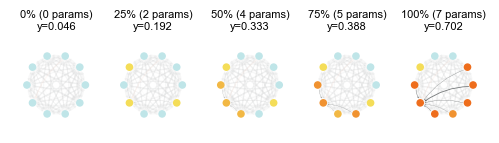

In [ ]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'axes.linewidth': 0.5,
    'legend.fontsize': 7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5,
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

paranum = df_results.shape[0]-1

snapshot_para = np.round(np.array([0,0.25,0.5,0.75,1])*paranum).astype(int)

selected_networks = []
selected_y = []

for k in snapshot_para:
    selected_networks.append(df_results["X"].iloc[k])
    selected_y.append(df_results["target_probability"].iloc[k])

global_gamma_max = 0
global_mu_min = np.inf
global_mu_max = -np.inf

for X in selected_networks:
    
    mu, gamma = unpack_X(X, n_real, MaxNum)
    global_gamma_max = max(global_gamma_max, np.abs(gamma).max())
    global_mu_min = min(global_mu_min, mu.min())
    global_mu_max = max(global_mu_max, mu.max())

changed_edges_list=[set()]
removed_edges_list=[set()]
changed_nodes_list=[set()]

edge_stage = {}
edge_stage_list = [{}]

node_stage = {}
node_stage_list = [{}]

for i in range(1, len(selected_networks)):    

    changed_edges, removed_edges, changed_nodes = get_changed_interactions(
        selected_networks[i-1],
        selected_networks[i],
        n_real,
        MaxNum,
        atol=1e-8
    )

    for e in changed_edges:
        edge_stage[e] = i

    for e in removed_edges:
        edge_stage[e] = i

    edge_stage_list.append(edge_stage.copy())

    for node in changed_nodes:
        node_stage[node] = i

    node_stage_list.append(node_stage.copy())

    cumulative_edges = (
        changed_edges_list[-1].copy()
        |
        changed_edges
    )

    cumulative_removed = (
        removed_edges_list[-1].copy()
        |
        removed_edges
    )

    cumulative_edges -= cumulative_removed

    changed_edges_list.append(cumulative_edges)
    removed_edges_list.append(cumulative_removed)

    cumulative_nodes = (
        changed_nodes_list[-1].copy()
        |
        changed_nodes
    )

    changed_nodes_list.append(cumulative_nodes)

changed_alphas = np.linspace(0.15, 0.95, len(selected_networks))

fig, axes = plt.subplots(1, 5, figsize=(6.0, 1.2))

progress = [0, 25, 50, 75, 100]

alpha_levels = np.linspace(0.05, 0.95, len(selected_networks))

for idx, (ax, X, y, p, k, changed_edges, changed_nodes) in enumerate(zip(
    axes,
    selected_networks,
    selected_y,
    progress,
    snapshot_para,
    changed_edges_list,
    changed_nodes_list
)):

    draw_network_snapshot(
        ax,
        X,
        n_real,
        global_gamma_max,
        global_mu_min,
        global_mu_max,

        gamma_threshold=0,

        changed_edges=changed_edges,
        removed_edges=removed_edges_list[idx],

        edge_stage=edge_stage_list[idx],
        alpha_levels=alpha_levels,

        node_stage=node_stage_list[idx],
    )

    ax.set_title(
        f"{p}% ({k} params)\n"
        f"y={y:.3f}"
    )

fig.subplots_adjust(
    left=0,
    right=0.8,
    bottom=0,
    top=0.8,
    wspace=0.05, 
    hspace=0.05 
)

plt.savefig(
    f"synbio_design_intra_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches="tight",
    transparent=True,
)

plt.show()


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from sklearn.decomposition import PCA
from datetime import datetime
import sys
sys.path.append("../../tools")
import prepare as prep
import generation as gr

NumSpecies = 10
Xnum = prep.recovery_Xnum(selected_networks[4], NumSpecies, MaxNum)


Total initializations: 100
Stable initializations: 100
Number of identified stable states: 1
Stable state 1: 100 initializations

Explained variance ratio:
[0.99179055 0.00308213]
Cumulative explained variance: 0.9948726761458005


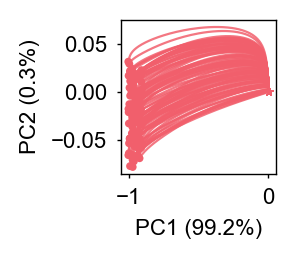

In [23]:
global NumSpecies,mu,gamma,D,delta

def MultiSpecies(t,y):
    thresh_y = 0
    dydt=np.zeros(NumSpecies)
    s=y
    s[s < thresh_y] = 0
    for i in range(NumSpecies):
        sumy_neg=0
        sumy_pos=0
        for j in range(NumSpecies):
            if gamma[i,j]<0:
                sumy_neg=sumy_neg+gamma[i,j]*s[j]
            if gamma[i,j]>0:
                sumy_pos=sumy_pos+gamma[i,j]*s[j]
        dydt[i]=mu[i]*s[i]*(1+sumy_neg+delta[i]*sumy_pos/(1+sumy_pos))+D[i]
    return dydt

wer = 0
featgam = NumSpecies**2 - NumSpecies
# mu
mu = Xnum[wer, 0:NumSpecies]

# gamma matrix
gamma = np.zeros((NumSpecies, NumSpecies))

indext = NumSpecies

for i in range(NumSpecies):
    for j in range(NumSpecies):
        if i == j:
            gamma[i, j] = -1
        else:
            gamma[i, j] = Xnum[wer, indext]
            indext += 1

# D
D = Xnum[wer, NumSpecies + featgam: NumSpecies + featgam + NumSpecies]

delta = 0.2 * np.ones(NumSpecies)

# ============================================================
# 4. Simulate multiple initializations
# ============================================================

timespan = np.arange(0, 800.1, 0.1)
n_initializations = 100
np.random.seed(42)
trajectory_list = []

for repeat in range(n_initializations):

    # Generate a new initial condition
    initial = np.random.rand(NumSpecies)/NumSpecies

    sol = solve_ivp(MultiSpecies, [0, max(timespan)], initial, method='RK45', t_eval=timespan, rtol=1e-6, atol=1e-9)

    if not sol.success:
        print(f"Initialization {repeat + 1} failed.")
        continue

    # Shape: (n_timepoints, NumSpecies)
    y = sol.y.T

    # Remove negative numerical values
    y[y < 0] = 0

    # Save the trajectory
    trajectory_list.append(y)

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.decomposition import PCA
from matplotlib.colors import to_hex


# ============================================================
# 5. Identify steady-state initializations
# ============================================================

# Keep the same sampling interval as the original analysis.
# Original sampling interval: every 20 integration steps.
sampling_interval = 20

stable_trajectory_list = []
stable_final_states = []

for trajectory in trajectory_list:

    # Reverse chronological order and downsample
    # This reproduces the original abundance sampling procedure.
    sampled_y = trajectory[::-sampling_interval, :]

    final_state = np.zeros(NumSpecies)
    all_species_stable = True

    for spc in range(NumSpecies):

        result = gr.classify_abundance(sampled_y[:, spc])

        if result[0] != 0:
            all_species_stable = False
            break

        final_state[spc] = result[1]

    # Keep only initializations where all species are steady
    if all_species_stable:

        stable_trajectory_list.append(trajectory)
        stable_final_states.append(final_state)

stable_final_states = np.array(stable_final_states)

n_stable_init = len(stable_trajectory_list)

print(f"Total initializations: {len(trajectory_list)}")
print(f"Stable initializations: {n_stable_init}")


# ============================================================
# 6. Cluster using the original Calculate_Index method
# ============================================================

if n_stable_init == 0:
    raise ValueError("No stable initializations were identified.")

cluster_threshold = 0.1

cluster_labels = gr.Calculate_Index(
    n_stable_init,
    stable_final_states,
    cluster_threshold
).astype(int)

n_clusters = int(np.max(cluster_labels))

print(f"Number of identified stable states: {n_clusters}")

for cluster_id in range(1, n_clusters + 1):

    indices = np.where(cluster_labels == cluster_id)[0]
    print(f"Stable state {cluster_id}: {len(indices)} initializations")

# ============================================================
# 7. Perform PCA on all stable trajectories
# ============================================================

all_states = np.concatenate(stable_trajectory_list, axis=0)

pca = PCA(n_components=2)

all_states_pca = pca.fit_transform(all_states)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)
print("Cumulative explained variance:", np.sum(pca.explained_variance_ratio_))

# Recover individual trajectories
n_timepoints = len(timespan)

trajectory_pca_list = []

for i in range(n_stable_init):

    start = i * n_timepoints
    end = (i + 1) * n_timepoints

    trajectory_pca_list.append(all_states_pca[start:end])


# ============================================================
# 8. Plot PCA trajectories using the original color palette
# ============================================================

colors = [
    '#F15F6C','#32BDA8','#EEB21C','#BFE5E8','#E8D0AE',
    '#D61F3E','#7297A0','#567589','#3E516F', 
]

# colors = [
#     '#BFE5E8', '#8CA06B', '#32BDA8', '#7297A0', 
#     '#567589', '#F15F6C', '#D61F3E', '#E8D0AE',
#     '#3E516F', '#EEB21C'
# ]

cluster_colors = {
    cluster_id: colors[(cluster_id - 1) % len(colors)]
    for cluster_id in range(1, n_clusters + 1)
}

fig, ax = plt.subplots(figsize=(1,1), dpi=200)

for i, trajectory_pca in enumerate(trajectory_pca_list):

    cluster_id = cluster_labels[i]
    color = cluster_colors[cluster_id]

    # Trajectory
    ax.plot(
        trajectory_pca[:, 0],
        trajectory_pca[:, 1],
        '-',
        linewidth=0.8,
        color=color,
        alpha=0.85
    )

    # Initial state
    ax.scatter(
        trajectory_pca[0, 0],
        trajectory_pca[0, 1],
        s=8,
        color=color,
        edgecolors='none',
        zorder=3
    )

    # Final state
    ax.scatter(
        trajectory_pca[-1, 0],
        trajectory_pca[-1, 1],
        s=12,
        color=color,
        marker='*',
        edgecolors='none',
        zorder=4
    )


ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")

ax.tick_params(
    axis='both',
    which='both',
    direction='out'
)

plt.savefig(
    f"PCA_trajectories_clustered_"
    f"{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf",
    dpi=1000,
    bbox_inches='tight',
    transparent=True
)

plt.show()
